In [1]:
# 1. Install dependencies and fetch the official book companion code
!pip -q install tiktoken gradio datasets tensorflow tqdm pdfplumber huggingface_hub

import os, sys, random, math, time, json
from pathlib import Path
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if not Path("/content/LLMs-from-scratch").exists():
    !git clone -q https://github.com/rasbt/LLMs-from-scratch.git /content/LLMs-from-scratch

sys.path.insert(0, "/content/LLMs-from-scratch/ch05/01_main-chapter-code")
from previous_chapters import GPTModel, generate_text_simple
from gpt_download import download_and_load_gpt2
import tiktoken
print("Course GPTModel and GPT-2 weight loader imported.")


Device: cpu
Course GPTModel and GPT-2 weight loader imported.


## 2. Load and preprocess CUAD contract PDFs
This cell downloads the CUAD dataset repository, selects up to 30 contract PDFs reproducibly using seed 42, extracts text, and reports the usable subset. The Hugging Face dataset loader is not used because the dataset stores contracts as PDFs and automatic decoding can fail.

In [2]:
from huggingface_hub import snapshot_download
import os, random, pdfplumber

SEED = 42
random.seed(SEED)
repo_dir = snapshot_download(
    repo_id="theatticusproject/cuad",
    repo_type="dataset",
    allow_patterns=["*.pdf", "**/*.pdf"]
)

pdf_files = []
for root, dirs, files_in_dir in os.walk(repo_dir):
    for name in files_in_dir:
        if name.lower().endswith(".pdf") and not any(
            word in name.lower() for word in ["readme", "datasheet"]
        ):
            pdf_files.append(os.path.join(root, name))

pdf_files = sorted(set(pdf_files))
random.shuffle(pdf_files)
selected_pdfs = pdf_files[:30]
texts = []
processed_files = []
for i, path in enumerate(selected_pdfs, start=1):
    try:
        with pdfplumber.open(path) as pdf:
            text = "\n".join(page.extract_text() or "" for page in pdf.pages)
        if len(text.strip()) >= 200:
            texts.append(text.strip())
            processed_files.append(os.path.basename(path))
    except Exception as exc:
        print("Skipped:", os.path.basename(path), "-", str(exc)[:100])
    if i % 5 == 0 or i == len(selected_pdfs):
        print(f"Processed {i}/{len(selected_pdfs)} selected PDFs")

if not texts:
    raise RuntimeError("No usable contract text extracted. Check the CUAD download and PDF files.")
print("Contract PDFs found:", len(pdf_files))
print("Selected PDFs:", len(selected_pdfs))
print("Usable contracts:", len(texts))
print("Total characters:", sum(len(t) for t in texts))
print("Preview:\n", texts[0][:500])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 200 files:   0%|          | 0/200 [00:00<?, ?it/s]

Processed 5/30 selected PDFs
Processed 10/30 selected PDFs
Processed 15/30 selected PDFs
Processed 20/30 selected PDFs
Processed 25/30 selected PDFs
Processed 30/30 selected PDFs
Contract PDFs found: 199
Selected PDFs: 30
Usable contracts: 30
Total characters: 1490515
Preview:
 Exhibit 10.2
CERTAIN INFORMATION (INDICATED BY ASTERISKS) HAS BEEN OMITTED FROM THIS DOCUMENT
BECAUSE IT IS NOT MATERIAL AND WOULD LIKELY CAUSE COMPETITIVE HARM TO THE REGISTRANT IF
PUBLICLY DISCLOSED.
Zogenix Inc.
and
Nippon Shinyaku Company Ltd.
Distributorship Agreement
US-DOCS\105216871.19
Source: ZOGENIX, INC., 10-Q, 5/9/2019
Table of Contents
Article 1. Definitions
Article 2. Grant of Rights
2.1 Grant of Rights to Distributor
2.2 Sub-distribution by Distributor
2.3 Supply of Product for Di


## 3. Tokenization and sliding-window DataLoader
We tokenize the extracted contract text using the GPT-2 BPE tokenizer. A contiguous 90/10 text split is used for training and validation, then next-token targets are shifted by one token. The selected PDF subset is randomized with seed 42.

In [12]:
import tiktoken
import torch
import numpy as np
import random
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Combine contract text
all_text = "\n\n".join(texts)

# Split into training and validation text
split_idx = int(0.9 * len(all_text))
train_text = all_text[:split_idx]
val_text = all_text[split_idx:]

# GPT-2 tokenizer
enc = tiktoken.get_encoding("gpt2")

train_ids = torch.tensor(enc.encode(train_text), dtype=torch.long)
val_ids = torch.tensor(enc.encode(val_text), dtype=torch.long)

print("Training tokens:", len(train_ids))
print("Validation tokens:", len(val_ids))

# Sliding-window dataset
CONTEXT_LENGTH = 256
STRIDE = 128
BATCH_SIZE = 2

class SlidingWindowDataset(Dataset):
    def __init__(self, token_ids, max_length=256, stride=128):
        self.token_ids = token_ids
        self.max_length = max_length
        self.stride = stride
        self.starts = list(
            range(0, len(token_ids) - max_length, stride)
        )

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, idx):
        i = self.starts[idx]
        x = self.token_ids[i:i + self.max_length]
        y = self.token_ids[i + 1:i + self.max_length + 1]
        return x, y

train_ds = SlidingWindowDataset(train_ids)
val_ds = SlidingWindowDataset(val_ids)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True
)

val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False
)

print("Training windows:", len(train_ds))
print("Validation windows:", len(val_ds))
print("Data loader ready!")

Device: cpu
Training tokens: 308220
Validation tokens: 34554
Training windows: 2406
Validation windows: 268
Data loader ready!


Total contracts: 30
Minimum tokens: 449
Maximum tokens: 40372
Average tokens: 11423.8


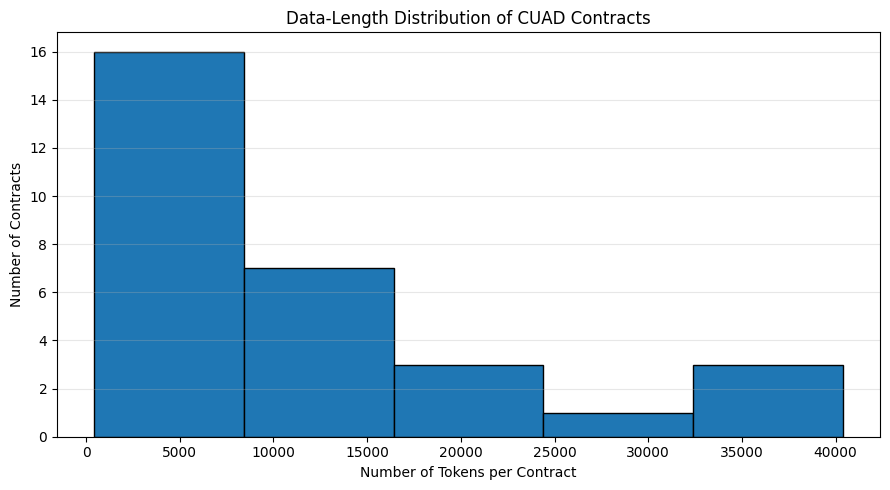

Histogram saved successfully!


In [13]:
import matplotlib.pyplot as plt
import numpy as np
import tiktoken

# Initialize GPT-2 tokenizer
enc = tiktoken.get_encoding("gpt2")

# Calculate token lengths from extracted contracts
contract_lengths = [len(enc.encode(text)) for text in texts]

# Display statistics
print("Total contracts:", len(contract_lengths))
print("Minimum tokens:", min(contract_lengths))
print("Maximum tokens:", max(contract_lengths))
print("Average tokens:", round(np.mean(contract_lengths), 2))

# Generate histogram
plt.figure(figsize=(9, 5))

plt.hist(contract_lengths, bins=5, edgecolor="black")

plt.title("Data-Length Distribution of CUAD Contracts")
plt.xlabel("Number of Tokens per Contract")
plt.ylabel("Number of Contracts")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("contract_data_length_histogram.png", dpi=300)
plt.show()

print("Histogram saved successfully!")

## 4. Initialize GPT-2 Small and load pretrained weights
This uses the course `GPTModel` and the textbook weight loader, not Hugging Face `AutoModel`, `Trainer`, or `pipeline`.

In [14]:
import sys
import torch

sys.path.insert(
    0, "/content/LLMs-from-scratch/ch05/01_main-chapter-code"
)

from previous_chapters import GPTModel
from gpt_download import download_and_load_gpt2

# Import the weight-loading function from its actual location
sys.path.insert(
    0, "/content/LLMs-from-scratch/ch05/01_main-chapter-code"
)

from gpt_generate import load_weights_into_gpt

GPT_CONFIG = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.0,
    "qkv_bias": True
}

model = GPTModel(GPT_CONFIG)

settings, params = download_and_load_gpt2(
    model_size="124M",
    models_dir="gpt2"
)

load_weights_into_gpt(model, params)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

print("GPT-2 loaded successfully!")
print("Device:", device)

checkpoint: 100%|██████████| 77.0/77.0 [00:00<00:00, 46.0kiB/s]
encoder.json: 100%|██████████| 1.04M/1.04M [00:00<00:00, 2.43MiB/s]
hparams.json: 100%|██████████| 90.0/90.0 [00:00<00:00, 150kiB/s]
model.ckpt.data-00000-of-00001: 100%|██████████| 498M/498M [02:10<00:00, 3.81MiB/s]
model.ckpt.index: 100%|██████████| 5.21k/5.21k [00:00<00:00, 7.25MiB/s]
model.ckpt.meta: 100%|██████████| 471k/471k [00:00<00:00, 2.18MiB/s]
vocab.bpe: 100%|██████████| 456k/456k [00:00<00:00, 1.28MiB/s]


GPT-2 loaded successfully!
Device: cpu


## 5. Evaluate before continued pretraining

In [15]:
import torch
import torch.nn.functional as F
import math
import numpy as np

@torch.no_grad()
def evaluate_loss(model, loader, max_batches=3):
    model.eval()
    losses = []

    for i, (x, y) in enumerate(loader):
        if i >= max_batches:
            break

        x = x.to(device)
        y = y.to(device)

        logits = model(x)
        loss = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            y.reshape(-1)
        )
        losses.append(loss.item())

    return float(np.mean(losses)) if losses else float("nan")

before_loss = evaluate_loss(model, val_loader, max_batches=3)
before_ppl = math.exp(min(before_loss, 20))

print("BEFORE TRAINING")
print("Validation loss:", round(before_loss, 4))
print("Perplexity:", round(before_ppl, 2))

BEFORE TRAINING
Validation loss: 3.3509
Perplexity: 28.53


## 6. Continued pretraining loop

In [16]:
import time
import torch

MAX_STEPS = 10
LEARNING_RATE = 5e-5

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.1
)

train_losses = []
step = 0
model.train()
start_time = time.time()

while step < MAX_STEPS:
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = torch.nn.functional.cross_entropy(
            logits.flatten(0, 1), y.flatten()
        )
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        train_losses.append(loss.item())
        step += 1

        print(f"Step {step}/{MAX_STEPS} | Loss: {loss.item():.4f}")

        if step >= MAX_STEPS:
            break

model.eval()
print(f"Training finished in {(time.time()-start_time)/60:.1f} minutes.")

Step 1/10 | Loss: 3.2902
Step 2/10 | Loss: 2.9191
Step 3/10 | Loss: 3.4675
Step 4/10 | Loss: 2.9906
Step 5/10 | Loss: 2.9498
Step 6/10 | Loss: 2.6261
Step 7/10 | Loss: 2.8591
Step 8/10 | Loss: 2.6588
Step 9/10 | Loss: 2.9352
Step 10/10 | Loss: 2.5697
Training finished in 1.6 minutes.


## 7. Evaluate after training and plot loss

In [17]:
after_loss = evaluate_loss(model, val_loader, max_batches=3)
after_ppl = math.exp(min(after_loss, 20))

print("AFTER TRAINING")
print("Validation loss:", round(after_loss, 4))
print("Perplexity:", round(after_ppl, 2))

print("\nCOMPARISON")
print(f"Before loss: {before_loss:.4f} | After loss: {after_loss:.4f}")
print(f"Before perplexity: {before_ppl:.2f} | After perplexity: {after_ppl:.2f}")

AFTER TRAINING
Validation loss: 3.0755
Perplexity: 21.66

COMPARISON
Before loss: 3.3509 | After loss: 3.0755
Before perplexity: 28.53 | After perplexity: 21.66


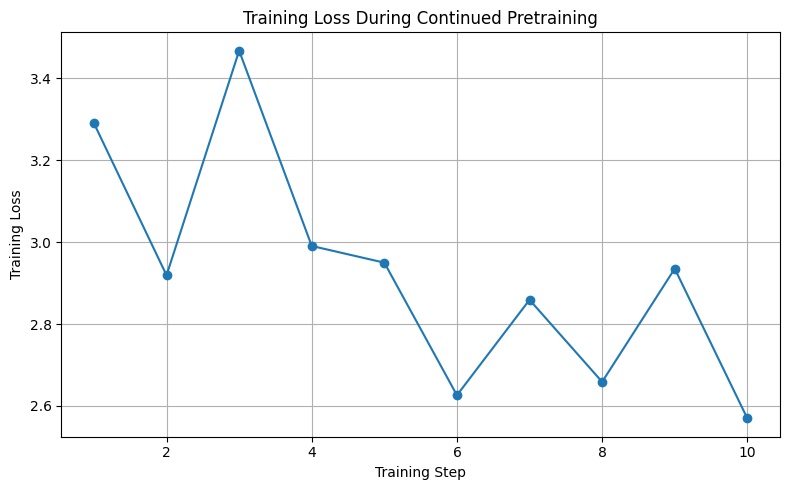

Loss curve saved to /content/training_loss_curve.png


In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, marker="o")
plt.title("Training Loss During Continued Pretraining")
plt.xlabel("Training Step")
plt.ylabel("Training Loss")
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/training_loss_curve.png", dpi=300)
plt.show()

print("Loss curve saved to /content/training_loss_curve.png")

## 8. Compare three decoding settings on the same prompts

In [19]:
@torch.no_grad()
def generate_completion(model, prompt, max_new_tokens=100, temperature=1.0, top_k=None, greedy=False):
    model.eval()
    idx = torch.tensor(enc.encode(prompt), dtype=torch.long, device=device).unsqueeze(0)
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -CONTEXT_LENGTH:]
        logits = model(idx_cond)[:, -1, :]
        if greedy:
            next_id = torch.argmax(logits, dim=-1, keepdim=True)
        else:
            logits = logits / max(temperature, 1e-5)
            if top_k is not None:
                k = min(top_k, logits.size(-1))
                vals, _ = torch.topk(logits, k)
                logits[logits < vals[:, [-1]]] = -float("inf")
            probs = torch.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
        idx = torch.cat([idx, next_id], dim=1)
    return enc.decode(idx[0].tolist())

prompts = [
    "The parties agree that either party may terminate this Agreement",
    "Confidential Information shall mean",
    "In the event of a breach of this Agreement"
]
for p in prompts:
    print("\n" + "="*90 + "\nPROMPT:", p)
    print("\n[Greedy]\n", generate_completion(model, p, max_new_tokens=70, greedy=True))
    print("\n[Temperature 0.8]\n", generate_completion(model, p, max_new_tokens=70, temperature=0.8))
    print("\n[Top-k 40, temperature 0.8]\n", generate_completion(model, p, max_new_tokens=70, temperature=0.8, top_k=40))



PROMPT: The parties agree that either party may terminate this Agreement

[Greedy]
 The parties agree that either party may terminate this Agreement at any time, subject to the terms and conditions set forth in this Agreement.

This Agreement is subject to the terms and conditions set forth in this Agreement.

This Agreement is subject to the terms and conditions set forth in this Agreement.

This Agreement is subject to the terms and conditions set forth in this Agreement.

This

[Temperature 0.8]
 The parties agree that either party may terminate this Agreement as a result of any of the following:

(i) Failure to provide party with the necessary follow-up notice to the other party.

(ii) The failure of the other party to provide adequate replacement documents and other support materials for the other party, including the full and complete reexamination of the original and proper investigation of the

[Top-k 40, temperature 0.8]
 The parties agree that either party may terminate this

## 9. Save and reload checkpoint
The checkpoint is saved locally for the reload test. Per the assignment instructions, do not include the weight file in the submitted deliverables.

In [20]:
CHECKPOINT_PATH = "/content/contract_gpt2_finetuned.pt"

torch.save({
    "model_state_dict": model.state_dict(),
    "config": GPT_CONFIG,
    "seed": SEED,
    "before_loss": before_loss,
    "after_loss": after_loss,
    "before_ppl": before_ppl,
    "after_ppl": after_ppl,
}, CHECKPOINT_PATH)

print("Saved:", CHECKPOINT_PATH)

reloaded = GPTModel(GPT_CONFIG).to(device)

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
reloaded.load_state_dict(checkpoint["model_state_dict"])
reloaded.eval()

print("Reload test:", generate_completion(
    reloaded,
    "The parties agree that either party may terminate this Agreement",
    max_new_tokens=40,
    greedy=True
))

Saved: /content/contract_gpt2_finetuned.pt
Reload test: The parties agree that either party may terminate this Agreement at any time, subject to the terms and conditions set forth in this Agreement.

This Agreement is subject to the terms and conditions set forth in this Agreement.

This Agreement is subject to


In [21]:
# Recreate GPT-2 model
reloaded = GPTModel(GPT_CONFIG).to(device)

# Load your saved checkpoint
checkpoint = torch.load(
    "/content/contract_gpt2_finetuned.pt",
    map_location=device,
    weights_only=False
)

reloaded.load_state_dict(checkpoint["model_state_dict"])
reloaded.eval()

print("Trained GPT-2 checkpoint loaded successfully!")

Trained GPT-2 checkpoint loaded successfully!


In [22]:
prompts_51 = [
    "The Receiving Party shall not disclose any Confidential Information to",
    "This Agreement shall be governed by and construed in accordance with the laws of",
    "Neither party shall be liable for any indirect, incidental or consequential damages arising",
    "The Licensor hereby grants to the Licensee a non-exclusive",
    "Payment shall be made within thirty (30) days of receipt of",
]
for n, p in enumerate(prompts_51, start=1):
    print(f"\n{'='*80}\nINPUT {n}: {p}\n")
    print(app_complete(p, "Top-k sampling", 70))


INPUT 1: The Receiving Party shall not disclose any Confidential Information to

The Receiving Party shall not disclose any Confidential Information to any other Party, other than after the Receiving Party has received a copy of the Confidential Information or any Additional Confidential Information submitted to the Receiving Party pursuant to Section 5(b)(3) of this Agreement.

(c) Except for any Confidential Information that the Receiving Party has received prior to the Effective Date, the

INPUT 2: This Agreement shall be governed by and construed in accordance with the laws of

This Agreement shall be governed by and construed in accordance with the laws of the State in which it was made, and the laws of the City in which it was made shall prevail in determining the validity of the Agreement. (h) Negotiating and Approval.--The Agreement shall be entered into, signed and executed by the State in which the Agreement is entered into and approved by the County Clerk in accordance with

## 10. Gradio application

In [23]:
import gradio as gr

def app_complete(prefix, strategy, max_new_tokens):
    if not prefix or not prefix.strip():
        return "Please enter the beginning of a contract clause."
    max_new_tokens = int(max_new_tokens)
    if strategy == "Greedy":
        return generate_completion(reloaded, prefix.strip(), max_new_tokens=max_new_tokens, greedy=True)
    if strategy == "Temperature sampling":
        return generate_completion(reloaded, prefix.strip(), max_new_tokens=max_new_tokens, temperature=0.8)
    return generate_completion(reloaded, prefix.strip(), max_new_tokens=max_new_tokens, temperature=0.8, top_k=40)

demo = gr.Interface(
    fn=app_complete,
    inputs=[
        gr.Textbox(lines=4, label="Contract clause prefix",
                   placeholder="The parties agree that either party may terminate this Agreement..."),
        gr.Radio(["Greedy", "Temperature sampling", "Top-k sampling"], value="Top-k sampling", label="Decoding strategy"),
        gr.Slider(minimum=20, maximum=150, value=70, step=10, label="Maximum new tokens")
    ],
    outputs=gr.Textbox(lines=10, label="Generated completion"),
    title="Contract Clause Autocompletion",
    description="Educational prototype only. Outputs may be inaccurate or fabricated; have all legal text reviewed by a qualified lawyer."
)
demo.launch(share=True, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fc32f5348959e9bd9a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 11. Verification and submission notes
This final cell checks the checkpoint and reports implementation details. The notebook should be run from top to bottom in a fresh Colab runtime before submission, and the resulting outputs should be saved.

In [ ]:
import os
print("GPTModel:", GPTModel.__module__)
print("Weight loader:", load_weights_into_gpt.__module__)
print("Custom sliding-window Dataset/DataLoader:", isinstance(train_ds, Dataset), isinstance(train_loader, DataLoader))
print("Custom training loop: yes")
print("Hugging Face Trainer/pipeline used for core model: no")
print("Checkpoint exists:", os.path.exists(CHECKPOINT_PATH))
if os.path.exists(CHECKPOINT_PATH):
    print("Checkpoint size (MB):", round(os.path.getsize(CHECKPOINT_PATH)/(1024**2), 2))
print("Training steps:", len(train_losses))
print("Before loss/perplexity:", round(before_loss, 4), round(before_ppl, 2))
print("After loss/perplexity:", round(after_loss, 4), round(after_ppl, 2))

GPTModel: previous_chapters
Weight loader: gpt_generate
Custom sliding-window Dataset/DataLoader: True True
Custom training loop: yes
Hugging Face Trainer/pipeline used for core model: no
Checkpoint exists: True
Checkpoint size (MB): 670.01
Training steps: 10
Before loss/perplexity: 3.3509 28.53
After loss/perplexity: 3.0755 21.66
